# Temperature sensors at the MAIO mast

Time series of every temperature measurement at the mast, 15 Sep to 12 Oct 2026, at 30-min resolution: first all sensors together, then one section per sensor compared with the ventilated Vaisala HMP110 at 4 m.

**Time convention.** All series are put in CEST, with each 30-min average stored under the *start* of its interval (15:00 holds 15:00 to 15:30):

| File | As stored | Shift applied |
|---|---|---|
| `profile.csv`, `cnr1.csv`, `FLUX_30min.csv` | CEST, end of interval | −30 min |
| `iws.csv` | UTC, end of interval | +2 h − 30 min |

Checked three ways: the daily shortwave peak of the CNR1 falls at 13:29 by its own clock and that of the CNR4 (in `iws.csv`) at 11:30, while solar noon in Utrecht is 11:29 UTC (13:29 CEST); `FLUX_30min.csv` has the same values as the datalogger file `turb.csv` under the same timestamps; and after these shifts the 30-min temperature changes of every sensor match the Vaisala best at zero lag.

**Cleaning**, following the README's *Problems found in the data*: the first, invalid record of the profile mast and CNR1 and the CNR1 record during the logger repair are dropped, the iWS fill value 327.67 is removed, the duplicated FLUX timestamp is kept once and thermocouple Tc values more than 3 K away from the sonic temperature are removed. The iWS thermocouples `TC1avg`/`TC2avg` are not used.

## Settings

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data")
FIGS = Path("../figures")
FIGS.mkdir(exist_ok=True)

# Chart style: light background, light grid, thin lines
INK = "#0b0b0b"     # reference series and titles
INK2 = "#52514e"    # labels
MUTED = "#898781"   # ticks and annotations
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 1.0, "legend.frameon": False, "legend.fontsize": 8.5,
    "figure.dpi": 110, "savefig.dpi": 150,
})

# One fixed colour per sensor, used in every figure
COLORS = {
    "iWS T sensor": "#2a78d6",
    "iWS RH/T sensor": "#eb6834",
    "Thermocouple Tc (sonic)": "#1baf7a",
    "Thermocouple Tc2 (propeller)": "#eda100",
    "Sonic temperature Ts": "#e87ba4",
    "CNR1 body": "#008300",
    "CNR4 body (iWS)": "#6250d6",
}
REFERENCE = "Vaisala HMP110 (ventilated)"

## Load the data and put it on one time axis

In [2]:
start_of_year = pd.Timestamp("2026-01-01")
half_hour = pd.Timedelta("30min")

# Profile mast: day of year (CEST, end of interval) -> start of interval
profile = pd.read_csv(DATA / "profile.csv")
profile.index = (start_of_year + pd.to_timedelta(profile.DOY - 1, unit="D")).dt.round("min") - half_hour
profile = profile[profile["T1"] > -10]   # drops the invalid first record

# CNR1 radiometer: same clock as the profile mast
cnr1 = pd.read_csv(DATA / "cnr1.csv")
cnr1.index = (start_of_year + pd.to_timedelta(cnr1.doy - 1, unit="D")).dt.round("min") - half_hour
cnr1 = cnr1[cnr1["SWTop_Avg"].between(-20, 1400)]   # drops 15 Sep 14:30 and 28 Sep 14:00

# iWS weather station: UTC, end of interval -> CEST, start of interval
iws = pd.read_csv(DATA / "iws.csv")
iws.index = pd.to_datetime(iws[["year", "mm", "dd", "hh", "minutes"]].rename(
    columns={"mm": "month", "dd": "day", "hh": "hour", "minutes": "minute"}))
iws.index = iws.index + pd.Timedelta("2h") - half_hour
iws = iws.replace(327.67, float("nan"))

# Sonic, thermocouples and propellers: CEST, end of interval -> start of interval; temperatures in K
flux = pd.read_csv(DATA / "FLUX_30min.csv", parse_dates=["Time"])
flux = flux.drop_duplicates("Time").set_index("Time")
flux.index = flux.index - half_hour
flux.loc[(flux["Tc"] - flux["Ts"]).abs() > 3, "Tc"] = float("nan")   # Tc spikes on 9 and 12 Oct

In [3]:
# Common 30-min time axis for the whole period
times = pd.date_range("2026-09-15 14:00", "2026-10-12 15:00", freq="30min")

# All temperatures in degC; the first column is the reference
temp = pd.DataFrame(index=times)
temp[REFERENCE] = profile["T2"]
temp["iWS T sensor"] = iws["THUTavg"]
temp["iWS RH/T sensor"] = iws["RHTavg"]
temp["Thermocouple Tc (sonic)"] = flux["Tc"] - 273.15
temp["Thermocouple Tc2 (propeller)"] = flux["Tc2"] - 273.15
temp["Sonic temperature Ts"] = flux["Ts"] - 273.15
temp["CNR1 body"] = cnr1["cnr1_T_C_Avg"]
temp["CNR4 body (iWS)"] = iws["NRTavg"]

# Vaisala profile, lowest first
prof = pd.DataFrame(index=times)
prof["0.5 m"] = profile["T5"]
prof["1 m"] = profile["T4"]
prof["2 m"] = profile["T3"]
prof["4 m"] = profile["T2"]
prof["8 m"] = profile["T1"]

temp.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Vaisala HMP110 (ventilated),1297.0,15.47,3.69,4.63,12.74,15.76,18.18,25.91
iWS T sensor,1272.0,15.29,3.85,4.36,12.40,15.52,18.16,26.07
iWS RH/T sensor,1272.0,15.55,4.53,3.44,11.90,15.71,18.90,27.57
Thermocouple Tc (sonic),789.0,15.91,3.29,8.03,13.64,16.02,18.07,25.54
Thermocouple Tc2 (propeller),1299.0,15.18,3.79,4.25,12.36,15.47,18.03,25.96
Sonic temperature Ts,1299.0,15.72,3.70,5.94,12.98,16.23,18.31,25.93
CNR1 body,1296.0,14.02,4.38,3.03,10.64,13.79,16.92,28.09
CNR4 body (iWS),1272.0,15.12,4.42,2.98,11.56,15.36,18.42,26.93


In [4]:
# Zoom window: the sunniest day (highest mean shortwave in) with one day either side
daily_sw = cnr1["SWTop_Avg"].resample("D").mean()
sunny_day = daily_sw.idxmax()
zoom_start = sunny_day - pd.Timedelta("1D")
zoom_end = sunny_day + pd.Timedelta("2D") - half_hour
print("Sunniest day:", sunny_day.date(), "| zoom window:", zoom_start.date(), "to", zoom_end.date())

Sunniest day: 2026-09-25 | zoom window: 2026-09-24 to 2026-09-26


## All air temperature sensors at about 4 m

Full period (top) and three days around the sunniest day (bottom). The ventilated Vaisala HMP110 is the reference, drawn in black.

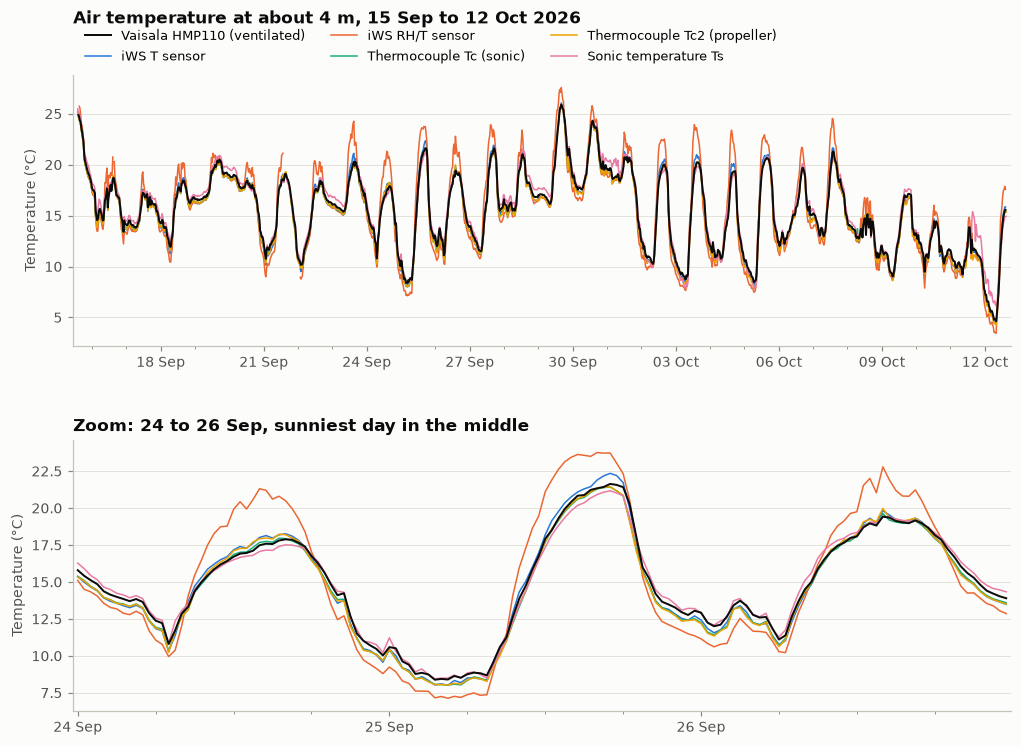

In [5]:
air_sensors = ["iWS T sensor", "iWS RH/T sensor", "Thermocouple Tc (sonic)",
               "Thermocouple Tc2 (propeller)", "Sonic temperature Ts"]

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(11, 7.5), gridspec_kw={"hspace": 0.35})
zoom = temp.loc[zoom_start:zoom_end]

ax_full.plot(temp.index, temp[REFERENCE], color=INK, lw=1.3, label=REFERENCE, zorder=3)
ax_zoom.plot(zoom.index, zoom[REFERENCE], color=INK, lw=1.3, zorder=3)
for column in air_sensors:
    ax_full.plot(temp.index, temp[column], color=COLORS[column], label=column)
    ax_zoom.plot(zoom.index, zoom[column], color=COLORS[column])

ax_full.set_title("Air temperature at about 4 m, 15 Sep to 12 Oct 2026", pad=34)
ax_full.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=3)
ax_full.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax_full.xaxis.set_minor_locator(mdates.DayLocator())
ax_full.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_zoom.set_title(f"Zoom: {zoom_start:%d} to {zoom_end:%d %b}, sunniest day in the middle")
ax_zoom.xaxis.set_major_locator(mdates.DayLocator())
ax_zoom.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_full.set_ylabel("Temperature (°C)")
ax_zoom.set_ylabel("Temperature (°C)")
ax_full.margins(x=0.005)
ax_zoom.margins(x=0.005)
fig.savefig(FIGS / "temperature_all_sensors.png", bbox_inches="tight")
plt.show()

## iWS T sensor

Temperature sensor in the radiation hut at the bottom of the unventilated, slightly translucent nylon iWS housing (`iws.csv`, `THUTavg`).

iWS T sensor minus Vaisala: mean -0.16 K, std 0.33 K, correlation 0.997, 1272 of 1299 values


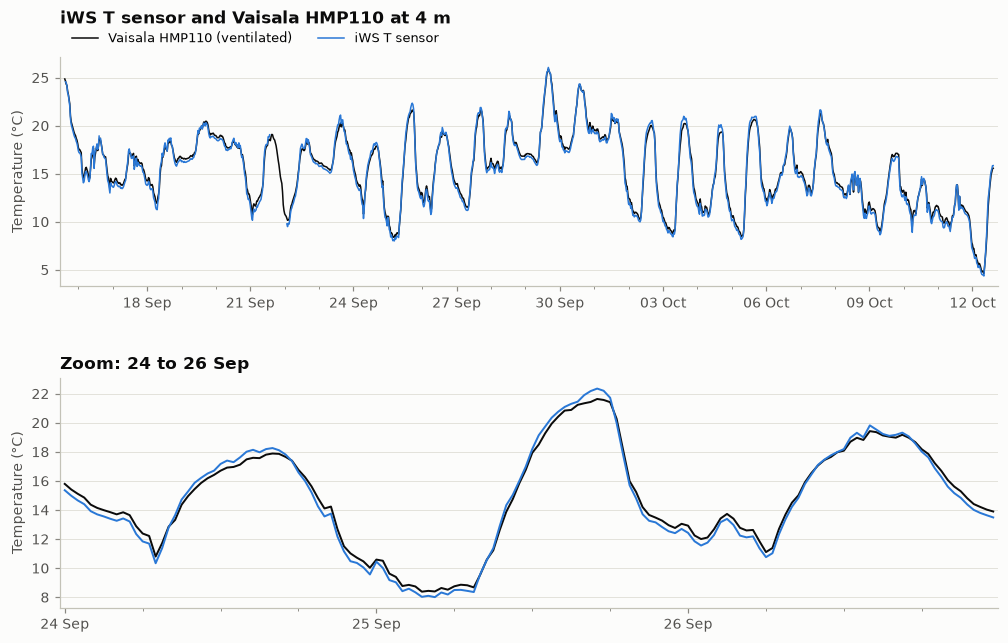

In [6]:
sensor = "iWS T sensor"
color = COLORS[sensor]
difference = temp[sensor] - temp[REFERENCE]
print(f"{sensor} minus Vaisala: mean {difference.mean():+.2f} K, "
      f"std {difference.std():.2f} K, correlation {temp[sensor].corr(temp[REFERENCE]):.3f}, "
      f"{temp[sensor].count()} of {len(temp)} values")

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(11, 6.5), gridspec_kw={"hspace": 0.4})
zoom = temp.loc[zoom_start:zoom_end]

ax_full.plot(temp.index, temp[REFERENCE], color=INK, lw=1.0, label=REFERENCE)
ax_full.plot(temp.index, temp[sensor], color=color, lw=1.0, label=sensor)
ax_zoom.plot(zoom.index, zoom[REFERENCE], color=INK, lw=1.3)
ax_zoom.plot(zoom.index, zoom[sensor], color=color, lw=1.3)

ax_full.set_title(f"{sensor} and Vaisala HMP110 at 4 m", pad=22)
ax_full.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2)
ax_full.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax_full.xaxis.set_minor_locator(mdates.DayLocator())
ax_full.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_zoom.set_title(f"Zoom: {zoom_start:%d} to {zoom_end:%d %b}")
ax_zoom.xaxis.set_major_locator(mdates.DayLocator())
ax_zoom.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_full.set_ylabel("Temperature (°C)")
ax_zoom.set_ylabel("Temperature (°C)")
ax_full.margins(x=0.005)
ax_zoom.margins(x=0.005)
fig.savefig(FIGS / "temperature_iws_t.png", bbox_inches="tight")
plt.show()

## iWS RH/T sensor

Temperature of the humidity sensor in the small chamber at the bottom of the iWS housing (`iws.csv`, `RHTavg`).

iWS RH/T sensor minus Vaisala: mean +0.10 K, std 1.33 K, correlation 0.968, 1272 of 1299 values


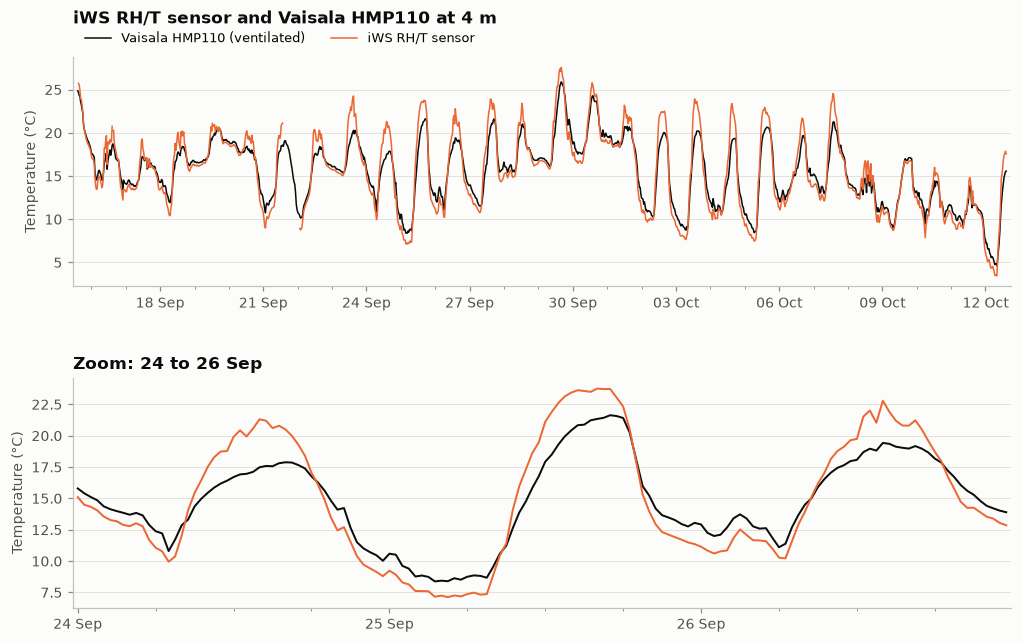

In [7]:
sensor = "iWS RH/T sensor"
color = COLORS[sensor]
difference = temp[sensor] - temp[REFERENCE]
print(f"{sensor} minus Vaisala: mean {difference.mean():+.2f} K, "
      f"std {difference.std():.2f} K, correlation {temp[sensor].corr(temp[REFERENCE]):.3f}, "
      f"{temp[sensor].count()} of {len(temp)} values")

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(11, 6.5), gridspec_kw={"hspace": 0.4})
zoom = temp.loc[zoom_start:zoom_end]

ax_full.plot(temp.index, temp[REFERENCE], color=INK, lw=1.0, label=REFERENCE)
ax_full.plot(temp.index, temp[sensor], color=color, lw=1.0, label=sensor)
ax_zoom.plot(zoom.index, zoom[REFERENCE], color=INK, lw=1.3)
ax_zoom.plot(zoom.index, zoom[sensor], color=color, lw=1.3)

ax_full.set_title(f"{sensor} and Vaisala HMP110 at 4 m", pad=22)
ax_full.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2)
ax_full.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax_full.xaxis.set_minor_locator(mdates.DayLocator())
ax_full.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_zoom.set_title(f"Zoom: {zoom_start:%d} to {zoom_end:%d %b}")
ax_zoom.xaxis.set_major_locator(mdates.DayLocator())
ax_zoom.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_full.set_ylabel("Temperature (°C)")
ax_zoom.set_ylabel("Temperature (°C)")
ax_full.margins(x=0.005)
ax_zoom.margins(x=0.005)
fig.savefig(FIGS / "temperature_iws_rht.png", bbox_inches="tight")
plt.show()

## Thermocouple Tc (sonic)

Fine-wire thermocouple next to the sonic anemometer (`FLUX_30min.csv`, `Tc`). Mostly missing from 29 Sep onward.

Thermocouple Tc (sonic) minus Vaisala: mean -0.24 K, std 0.20 K, correlation 0.998, 789 of 1299 values


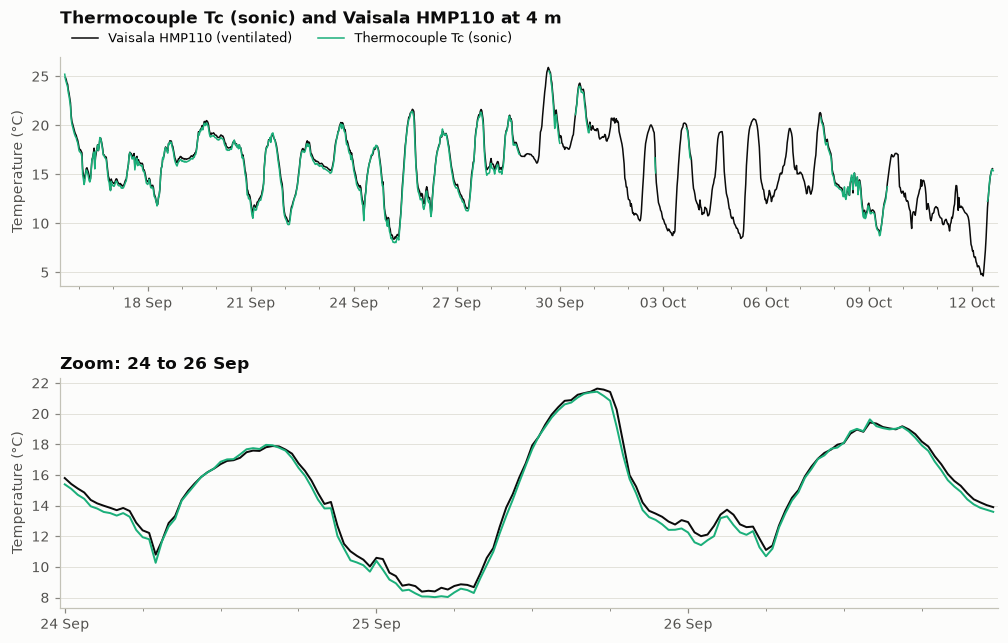

In [8]:
sensor = "Thermocouple Tc (sonic)"
color = COLORS[sensor]
difference = temp[sensor] - temp[REFERENCE]
print(f"{sensor} minus Vaisala: mean {difference.mean():+.2f} K, "
      f"std {difference.std():.2f} K, correlation {temp[sensor].corr(temp[REFERENCE]):.3f}, "
      f"{temp[sensor].count()} of {len(temp)} values")

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(11, 6.5), gridspec_kw={"hspace": 0.4})
zoom = temp.loc[zoom_start:zoom_end]

ax_full.plot(temp.index, temp[REFERENCE], color=INK, lw=1.0, label=REFERENCE)
ax_full.plot(temp.index, temp[sensor], color=color, lw=1.0, label=sensor)
ax_zoom.plot(zoom.index, zoom[REFERENCE], color=INK, lw=1.3)
ax_zoom.plot(zoom.index, zoom[sensor], color=color, lw=1.3)

ax_full.set_title(f"{sensor} and Vaisala HMP110 at 4 m", pad=22)
ax_full.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2)
ax_full.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax_full.xaxis.set_minor_locator(mdates.DayLocator())
ax_full.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_zoom.set_title(f"Zoom: {zoom_start:%d} to {zoom_end:%d %b}")
ax_zoom.xaxis.set_major_locator(mdates.DayLocator())
ax_zoom.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_full.set_ylabel("Temperature (°C)")
ax_zoom.set_ylabel("Temperature (°C)")
ax_full.margins(x=0.005)
ax_zoom.margins(x=0.005)
fig.savefig(FIGS / "temperature_tc.png", bbox_inches="tight")
plt.show()

## Thermocouple Tc2 (propeller)

Fine-wire thermocouple next to the vertical propeller (`FLUX_30min.csv`, `Tc2`); its height is not documented.

Thermocouple Tc2 (propeller) minus Vaisala: mean -0.29 K, std 0.24 K, correlation 0.998, 1299 of 1299 values


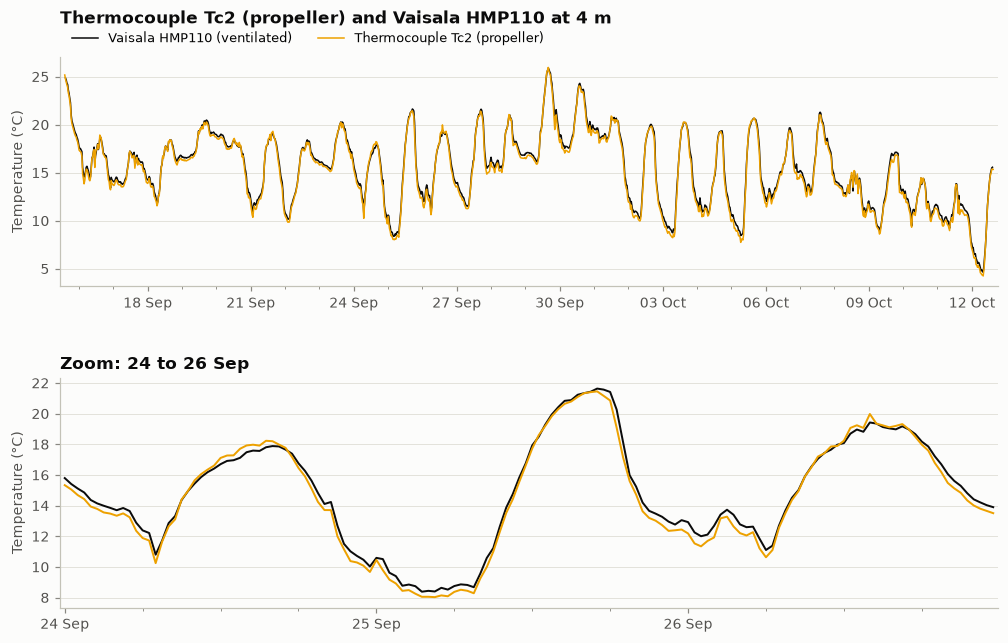

In [9]:
sensor = "Thermocouple Tc2 (propeller)"
color = COLORS[sensor]
difference = temp[sensor] - temp[REFERENCE]
print(f"{sensor} minus Vaisala: mean {difference.mean():+.2f} K, "
      f"std {difference.std():.2f} K, correlation {temp[sensor].corr(temp[REFERENCE]):.3f}, "
      f"{temp[sensor].count()} of {len(temp)} values")

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(11, 6.5), gridspec_kw={"hspace": 0.4})
zoom = temp.loc[zoom_start:zoom_end]

ax_full.plot(temp.index, temp[REFERENCE], color=INK, lw=1.0, label=REFERENCE)
ax_full.plot(temp.index, temp[sensor], color=color, lw=1.0, label=sensor)
ax_zoom.plot(zoom.index, zoom[REFERENCE], color=INK, lw=1.3)
ax_zoom.plot(zoom.index, zoom[sensor], color=color, lw=1.3)

ax_full.set_title(f"{sensor} and Vaisala HMP110 at 4 m", pad=22)
ax_full.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2)
ax_full.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax_full.xaxis.set_minor_locator(mdates.DayLocator())
ax_full.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_zoom.set_title(f"Zoom: {zoom_start:%d} to {zoom_end:%d %b}")
ax_zoom.xaxis.set_major_locator(mdates.DayLocator())
ax_zoom.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_full.set_ylabel("Temperature (°C)")
ax_zoom.set_ylabel("Temperature (°C)")
ax_full.margins(x=0.005)
ax_zoom.margins(x=0.005)
fig.savefig(FIGS / "temperature_tc2.png", bbox_inches="tight")
plt.show()

## Sonic temperature Ts

Sonic temperature from the speed of sound (`FLUX_30min.csv`, `Ts`); close to the virtual temperature, so slightly above the air temperature in humid air.

Sonic temperature Ts minus Vaisala: mean +0.25 K, std 0.46 K, correlation 0.992, 1299 of 1299 values


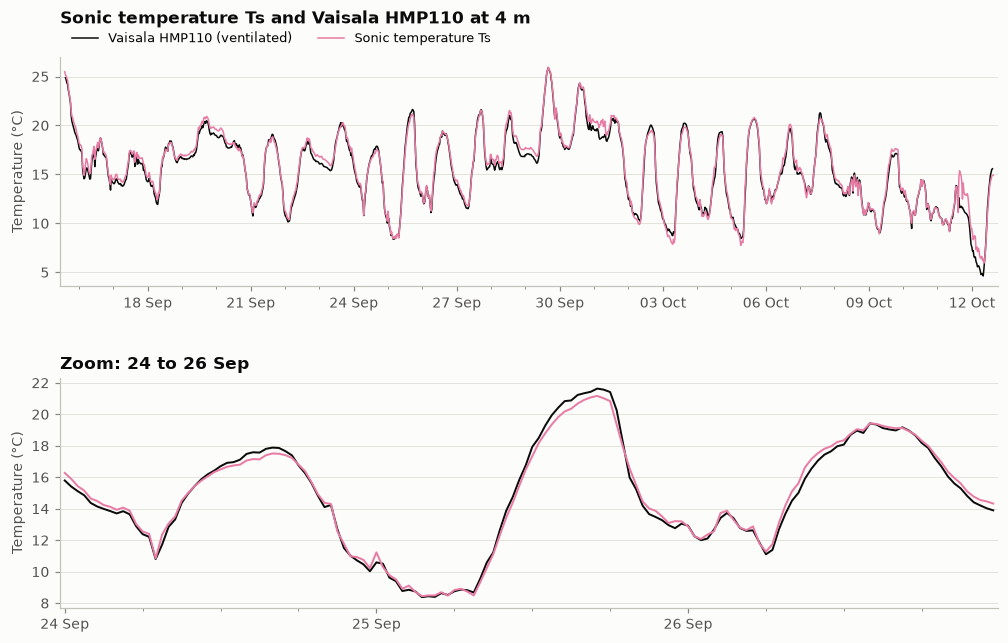

In [10]:
sensor = "Sonic temperature Ts"
color = COLORS[sensor]
difference = temp[sensor] - temp[REFERENCE]
print(f"{sensor} minus Vaisala: mean {difference.mean():+.2f} K, "
      f"std {difference.std():.2f} K, correlation {temp[sensor].corr(temp[REFERENCE]):.3f}, "
      f"{temp[sensor].count()} of {len(temp)} values")

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(11, 6.5), gridspec_kw={"hspace": 0.4})
zoom = temp.loc[zoom_start:zoom_end]

ax_full.plot(temp.index, temp[REFERENCE], color=INK, lw=1.0, label=REFERENCE)
ax_full.plot(temp.index, temp[sensor], color=color, lw=1.0, label=sensor)
ax_zoom.plot(zoom.index, zoom[REFERENCE], color=INK, lw=1.3)
ax_zoom.plot(zoom.index, zoom[sensor], color=color, lw=1.3)

ax_full.set_title(f"{sensor} and Vaisala HMP110 at 4 m", pad=22)
ax_full.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2)
ax_full.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax_full.xaxis.set_minor_locator(mdates.DayLocator())
ax_full.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_zoom.set_title(f"Zoom: {zoom_start:%d} to {zoom_end:%d %b}")
ax_zoom.xaxis.set_major_locator(mdates.DayLocator())
ax_zoom.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_full.set_ylabel("Temperature (°C)")
ax_zoom.set_ylabel("Temperature (°C)")
ax_full.margins(x=0.005)
ax_zoom.margins(x=0.005)
fig.savefig(FIGS / "temperature_ts.png", bbox_inches="tight")
plt.show()

## CNR1 body

Body temperature of the CNR1 radiometer (`cnr1.csv`, `cnr1_T_C_Avg`), biased until the logger repair on 28 Sep (dashed line).

CNR1 body minus Vaisala: mean -1.45 K, std 1.53 K, correlation 0.942, 1296 of 1299 values


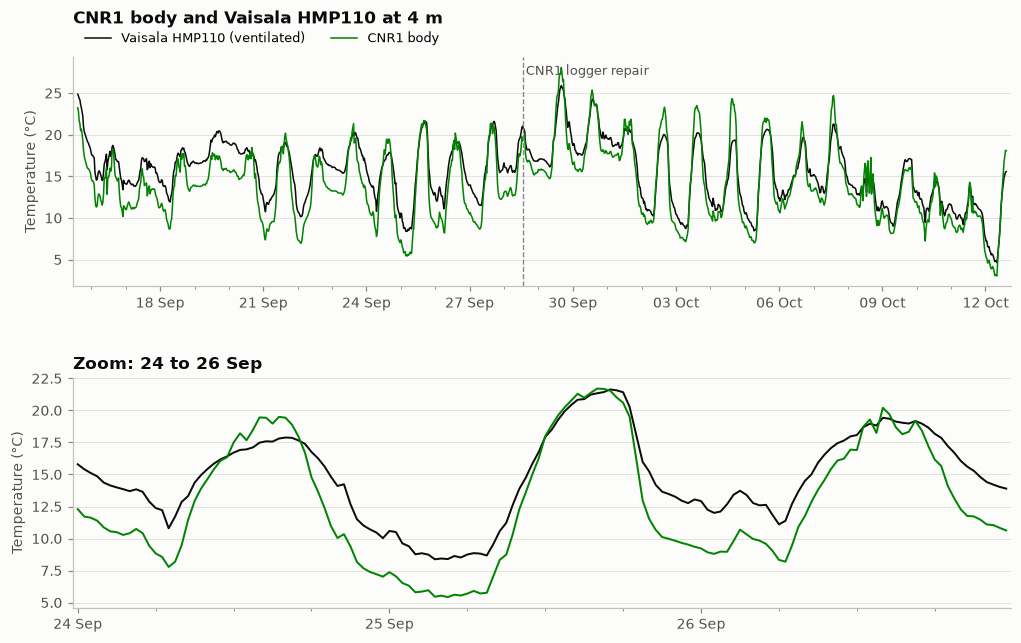

In [11]:
sensor = "CNR1 body"
color = COLORS[sensor]
difference = temp[sensor] - temp[REFERENCE]
print(f"{sensor} minus Vaisala: mean {difference.mean():+.2f} K, "
      f"std {difference.std():.2f} K, correlation {temp[sensor].corr(temp[REFERENCE]):.3f}, "
      f"{temp[sensor].count()} of {len(temp)} values")

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(11, 6.5), gridspec_kw={"hspace": 0.4})
zoom = temp.loc[zoom_start:zoom_end]

ax_full.plot(temp.index, temp[REFERENCE], color=INK, lw=1.0, label=REFERENCE)
ax_full.plot(temp.index, temp[sensor], color=color, lw=1.0, label=sensor)
ax_zoom.plot(zoom.index, zoom[REFERENCE], color=INK, lw=1.3)
ax_zoom.plot(zoom.index, zoom[sensor], color=color, lw=1.3)

repair = pd.Timestamp("2026-09-28 13:15")
ax_full.axvline(repair, color=MUTED, lw=0.9, ls="--")
ax_full.text(repair + pd.Timedelta("2h"), 0.97, "CNR1 logger repair", transform=ax_full.get_xaxis_transform(),
             va="top", color=INK2, fontsize=8.5)

ax_full.set_title(f"{sensor} and Vaisala HMP110 at 4 m", pad=22)
ax_full.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2)
ax_full.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax_full.xaxis.set_minor_locator(mdates.DayLocator())
ax_full.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_zoom.set_title(f"Zoom: {zoom_start:%d} to {zoom_end:%d %b}")
ax_zoom.xaxis.set_major_locator(mdates.DayLocator())
ax_zoom.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_full.set_ylabel("Temperature (°C)")
ax_zoom.set_ylabel("Temperature (°C)")
ax_full.margins(x=0.005)
ax_zoom.margins(x=0.005)
fig.savefig(FIGS / "temperature_cnr1_body.png", bbox_inches="tight")
plt.show()

## CNR4 body (iWS)

Body temperature of the CNR4 radiometer on the iWS station (`iws.csv`, `NRTavg`).

CNR4 body (iWS) minus Vaisala: mean -0.34 K, std 1.11 K, correlation 0.978, 1272 of 1299 values


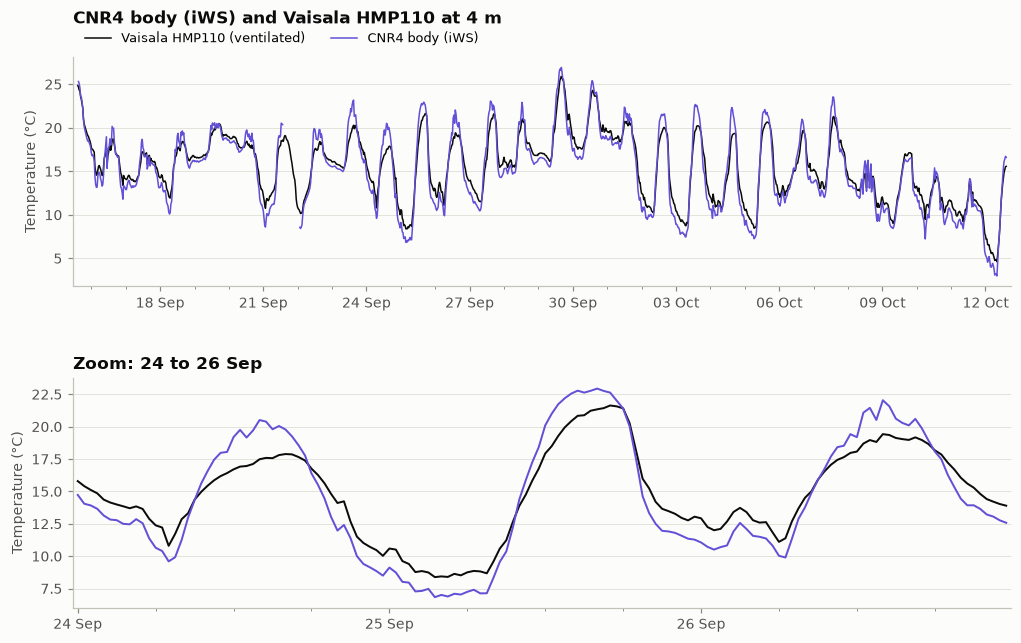

In [12]:
sensor = "CNR4 body (iWS)"
color = COLORS[sensor]
difference = temp[sensor] - temp[REFERENCE]
print(f"{sensor} minus Vaisala: mean {difference.mean():+.2f} K, "
      f"std {difference.std():.2f} K, correlation {temp[sensor].corr(temp[REFERENCE]):.3f}, "
      f"{temp[sensor].count()} of {len(temp)} values")

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(11, 6.5), gridspec_kw={"hspace": 0.4})
zoom = temp.loc[zoom_start:zoom_end]

ax_full.plot(temp.index, temp[REFERENCE], color=INK, lw=1.0, label=REFERENCE)
ax_full.plot(temp.index, temp[sensor], color=color, lw=1.0, label=sensor)
ax_zoom.plot(zoom.index, zoom[REFERENCE], color=INK, lw=1.3)
ax_zoom.plot(zoom.index, zoom[sensor], color=color, lw=1.3)

ax_full.set_title(f"{sensor} and Vaisala HMP110 at 4 m", pad=22)
ax_full.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2)
ax_full.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax_full.xaxis.set_minor_locator(mdates.DayLocator())
ax_full.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_zoom.set_title(f"Zoom: {zoom_start:%d} to {zoom_end:%d %b}")
ax_zoom.xaxis.set_major_locator(mdates.DayLocator())
ax_zoom.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_full.set_ylabel("Temperature (°C)")
ax_zoom.set_ylabel("Temperature (°C)")
ax_full.margins(x=0.005)
ax_zoom.margins(x=0.005)
fig.savefig(FIGS / "temperature_cnr4_body.png", bbox_inches="tight")
plt.show()

## Vaisala HMP110 profile

The five ventilated sensors from 0.5 to 8 m; darker is higher.

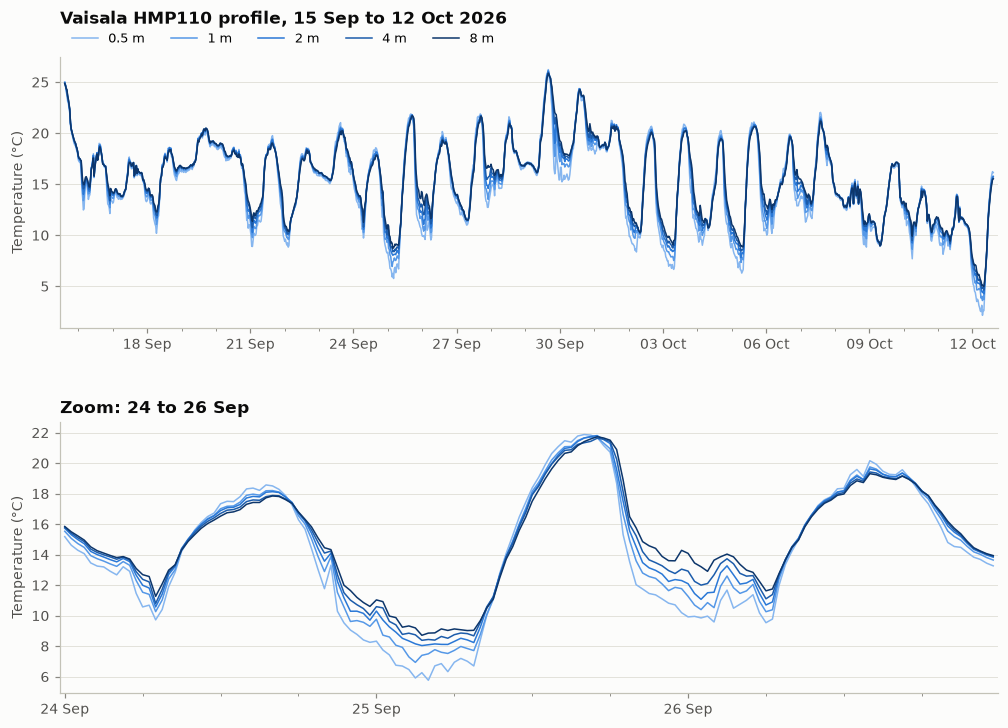

In [13]:
# Blue shades from light (low) to dark (high)
blues = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(11, 7.5), gridspec_kw={"hspace": 0.35})
zoom = prof.loc[zoom_start:zoom_end]

for column, color in zip(prof.columns, blues):
    ax_full.plot(prof.index, prof[column], color=color, label=column)
    ax_zoom.plot(zoom.index, zoom[column], color=color)

ax_full.set_title("Vaisala HMP110 profile, 15 Sep to 12 Oct 2026", pad=22)
ax_full.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=5)
ax_full.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax_full.xaxis.set_minor_locator(mdates.DayLocator())
ax_full.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_zoom.set_title(f"Zoom: {zoom_start:%d} to {zoom_end:%d %b}")
ax_zoom.xaxis.set_major_locator(mdates.DayLocator())
ax_zoom.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax_full.set_ylabel("Temperature (°C)")
ax_zoom.set_ylabel("Temperature (°C)")
ax_full.margins(x=0.005)
ax_zoom.margins(x=0.005)
fig.savefig(FIGS / "temperature_profile.png", bbox_inches="tight")
plt.show()